# 03 – Classification of termination reasons ("Why Stopped")

**Input:** `data/processed/ctgov_analysis_dataset.parquet` – the 1,154 terminated trials.

**Approach:** transparent, rule-based classification (D07, D08). Every assignment can be traced
back to the keyword pattern that triggered it (`mappings/why_stopped_keywords.csv`).

| Category | Meaning |
|---|---|
| Safety | adverse events, toxicity, tolerability, deaths, benefit-risk, non-clinical safety findings |
| Efficacy/Futility | lack of efficacy, futility, endpoint not met |
| Recruitment | slow / insufficient recruitment or enrolment, feasibility |
| Funding | funding, financial reasons |
| Strategic/Business | business / strategic decisions, portfolio, development programme stopped |
| COVID-19 | the COVID-19 pandemic is named as a reason (own category, D35) |
| Sponsor decision (unspecified) | "sponsor decision" without any further reason – own category (decided 29 Oct 2026) |
| Other | supply, regulatory, site/investigator, design change, phase transition, objectives met, … |
| Not stated | no reason given, or an uninformative text ("Terminated") |

**Negation handling:** a keyword is ignored if, in the same clause, a negation cue (no, not,
without, unrelated, …) precedes it – unless a causal connector ("due to", "because", …)
starts a new statement in between (*"not proceeding to Phase 2 **due to** safety findings"*).
Expressions in which the negation *is* the reason (*"no efficacy"*, *"not enough patients"*,
*"lack of funding"*) are part of the keyword patterns themselves.

Blocks: **B8** (this notebook: rules, tests, classification) · **B9/B10** (manual validation).

In [1]:
# --- Setup -------------------------------------------------------------------
import re
from pathlib import Path

import pandas as pd

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 160)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_DIR / "data" / "processed"

data = pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet")
term = data[data["terminated"] == 1][["nct_id", "why_stopped", "start_year", "healthy_volunteers",
                                      "indication_group", "industry_sponsor"]].copy()
keywords = pd.read_csv(PROJECT_DIR / "mappings" / "why_stopped_keywords.csv")
print(f"Terminated trials: {len(term):,} | without why_stopped: {term['why_stopped'].isna().sum()}")
print(f"Keyword patterns : {len(keywords)} in {keywords['category'].nunique()} categories")

Terminated trials: 1,154 | without why_stopped: 131
Keyword patterns : 65 in 9 categories


## 1. Classification rules

In [2]:
CATEGORIES = ["Safety", "Efficacy/Futility", "COVID-19", "Recruitment", "Funding", "Strategic/Business",
              "Sponsor decision (unspecified)", "Other", "Not stated"]
# Priority for the single primary reason (medically most relevant first; COVID-19 before
# recruitment/business because it is usually the root cause of those problems)
PRIMARY_PRIORITY = CATEGORIES

NEGATION_CUE = re.compile(r"\b(no|not|non|none|neither|nor|without|unrelated|never|nothing)\b|n't\b")
CAUSAL = re.compile(r"\b(due to|because|owing to|as a result of|based on|following|caused by|given|for|since)\b")
CLAUSE_SPLIT = re.compile(r"[.;!?\n]|:(?=\s)|\bbut\b|\bhowever\b|\balthough\b|\bwhereas\b|\binstead\b|\brather\b")
UNINFORMATIVE = re.compile(
    r"^(the )?(study|trial)?\s*(was |has been |is )?(terminated|stopped|ended|closed|discontinued|halted)?"
    r"\s*(early|prematurely)?\s*(by sponsor)?$|^(early )?termination$"
    r"|^(n/?a|na|none|other|unknown)$|^see .{0,40}(above|below|description)$")

# v2 (after expert validation)
TERMINATION_WORDS = re.compile(r"((being|been|is|was|were|the|study|trial|terminated|stopped|discontinued|halted|"
                               r"closed|ended|prematurely|early)\s*)+")
NEUTRAL_SAFETY_CONTEXT = re.compile(
    r"\b(characteri[sz]\w*|sufficient\w*|enough|acceptable|manageable|adequate\w*|well[- ]established|"
    r"established|consistent|collected|demonstrated|no need|unchanged|reassuring|analy[sz]e|analysis of|"
    r"followed up|follow[- ]?up|f-?up|improv\w*)\b")

PATTERNS = [(r.category, re.compile(r.pattern, re.I), r.flag if isinstance(r.flag, str) else None, r.pattern)
            for r in keywords.itertuples()]


def is_negated(clause, match_start):
    """True if a negation cue before the match (in the same clause) still applies to it."""
    before = clause[:match_start]
    cues = list(NEGATION_CUE.finditer(before))
    if not cues:
        return False
    between = before[cues[-1].end():]
    causal = CAUSAL.search(between)
    # A causal connector after at least one other word ends the scope of the negation:
    # "not proceeding to phase 2 due to safety"  -> not negated
    # "not due to safety"                         -> negated
    if causal:
        words_before = between[:causal.start()].strip()
        # v2: words that only describe the termination itself keep the negation alive:
        # "not terminated due to a safety reason" / "is not being terminated for safety"
        if words_before and not TERMINATION_WORDS.fullmatch(words_before):
            return False
    return True


def neutral_safety(clause, matched_text, flag):
    """v2: generic safety / tolerability / benefit-risk wording used as information, not as a reason."""
    generic = re.fullmatch(r"safety|tolerability", matched_text.strip()) or flag == "benefit_risk"
    return bool(generic and NEUTRAL_SAFETY_CONTEXT.search(clause))


def classify(text):
    result = {c: 0 for c in CATEGORIES}
    flags, hits, negated = set(), [], []
    if not isinstance(text, str) or not text.strip():
        result["Not stated"] = 1
        return result, flags, hits, negated
    clean = re.sub(r"\s+", " ", text.lower().replace("\\&", "&")).strip()
    # "non-clinical" and "non-favorable" are not negations of the following keyword
    clean = re.sub(r"\bnon[- ]?clinical\b", "nonclinical", clean)
    clean = re.sub(r"\bnon[- ]?favou?rable\b", "unfavorable", clean)
    if UNINFORMATIVE.match(clean.rstrip(". ")):
        result["Not stated"] = 1
        return result, flags, ["uninformative text"], negated

    for clause in CLAUSE_SPLIT.split(clean):
        for category, pattern, flag, raw in PATTERNS:
            for m in pattern.finditer(clause):
                if is_negated(clause, m.start()):
                    negated.append(f"{category}: '{m.group(0)}'")
                    continue
                if category == "Safety" and neutral_safety(clause, m.group(0), flag):
                    negated.append(f"Safety (information, not a reason): '{m.group(0)}'")
                    continue
                result[category] = 1
                hits.append(f"{category}: '{m.group(0)}'")
                if flag:
                    flags.add(flag)

    # "Sponsor decision" counts only if no other substantive reason was found
    substantive = [c for c in CATEGORIES if c not in ("Sponsor decision (unspecified)", "Not stated") and result[c]]
    if result["Sponsor decision (unspecified)"] and substantive:
        result["Sponsor decision (unspecified)"] = 0
    if not any(result.values()):
        result["Other"] = 1
        flags.add("unmatched")
    return result, flags, hits, negated


def primary_reason(result):
    return next(c for c in PRIMARY_PRIORITY if result[c])

## 2. Tests – expected behaviour on typical sentences

These assertions document how the rules handle negations and multiple reasons. If a rule
change breaks one of them, the notebook stops.

In [3]:
TESTS = [
    ("Safety issues", {"Safety"}),
    ("There were no safety concerns that contributed to this decision. Business decision.", {"Strategic/Business"}),
    ("The decision was part of a strategic review. It is not related to any safety concerns, efficacy findings, "
     "recruitment difficulties, or issues with trial conduct.", {"Strategic/Business"}),
    ("Lack of efficacy", {"Efficacy/Futility"}),
    ("No efficacy signal observed at interim analysis", {"Efficacy/Futility"}),
    ("Not enough patients could be enrolled", {"Recruitment"}),
    ("Slow recruitment and sponsor's strategic decision", {"Recruitment", "Strategic/Business"}),
    ("Sponsor decision", {"Sponsor decision (unspecified)"}),
    ("Sponsor decision due to slow accrual", {"Recruitment"}),
    ("Not proceeding to Phase 2 due to safety findings", {"Safety", "Other"}),
    ("Terminated not due to safety but due to lack of funding", {"Funding"}),
    ("poor tolerability at highest dose", {"Safety"}),
    ("The drug was well tolerated; development stopped for business reasons", {"Strategic/Business"}),
    ("COVID-19 pandemic", {"COVID-19"}),
    ("Very slow recruitment of patients and the current COVID-19 pandemic situation.", {"Recruitment", "COVID-19"}),
    ("Terminated", {"Not stated"}),
    (None, {"Not stated"}),
    ("This study has been terminated due to meeting protocol defined futility.", {"Efficacy/Futility"}),
    ("Target number of inclusion not reached", {"Recruitment"}),
    ("The study was terminated after the risk:benefit ratio no longer favored continued evaluation.", {"Safety"}),
    ("Study terminated because the clinical development programme has been discontinued", {"Strategic/Business"}),
    ("Despite efforts to boost recruitment, no new patients were enrolled.", {"Recruitment"}),
    ("Study objectives met so study concluded earlier than planned", {"Other"}),
    ("early termination", {"Not stated"}),
    ("The clinical trial is closed due to cessation of activities. This closure is not due to safety reasons.",
     {"Strategic/Business"}),
    ("As no safety warnings were detected, interim analysis recommends to stop the trial for futility",
     {"Efficacy/Futility"}),
    ("Non-favorable risk/benefit profile with studied dosing regimen", {"Safety"}),
    ("Terminated due to non clinical toxicology findings and reduced safety margins.", {"Safety"}),
    ("Group B not started for business reasons.", {"Strategic/Business", "Other"}),
    ("Terminated due to limited anti-cancer activity", {"Efficacy/Futility"}),
    ("only one patient enrolled", {"Recruitment"}),
    ("Sponsor terminated the study for non-safety reasons", {"Sponsor decision (unspecified)"}),
    # v2 (after expert validation)
    ("Terminated (Decision by the Sponsor. The study was not terminated due to a safety reason.)",
     {"Sponsor decision (unspecified)"}),
    ("Due to portfolio issues, this study will not be re-started. The study is not being terminated for safety reasons.",
     {"Strategic/Business"}),
    ("Enough data has been collected to allow analysis of the safety profile and risk-benefit.", {"Other"}),
    ("Primary objective has been met; safety and pharmacokinetics have been characterized.", {"Other"}),
    ("Trial terminated based on benefit-risk profile assessment", {"Safety"}),
    ("Lack of favorable benefit risk ratio in another study", {"Safety", "Efficacy/Futility"}),
    ("No safety concerns or efficacy observations led to this study closure. Company is no longer pursuing "
     "oncology indications.", {"Strategic/Business"}),
    ("Recruitment of chronic opioid users was substantially lower than anticipated", {"Recruitment"}),
    ("Takeda has decided to not further develop the program", {"Strategic/Business"}),
    ("Ended prematurely - The trial never commenced.", {"Not stated"}),
]
failures = []
for text, expected in TESTS:
    res, _, hits, neg = classify(text)
    got = {c for c, v in res.items() if v}
    if got != expected:
        failures.append((text, expected, got, hits, neg))
for f in failures:
    print("FAIL:", f)
assert not failures, f"{len(failures)} test(s) failed"
print(f"All {len(TESTS)} tests passed")

All 42 tests passed


## 3. Classify all terminated trials

In [4]:
rows = []
for nct, text in zip(term["nct_id"], term["why_stopped"]):
    res, flags, hits, negated = classify(text)
    rows.append({"nct_id": nct, **{f"reason_{c}": v for c, v in res.items()},
                 "reason_categories": "|".join(c for c in CATEGORIES if res[c]),
                 "n_reasons": sum(res.values()),
                 "primary_reason": primary_reason(res),
                 "reason_flags": "|".join(sorted(flags)) or None,
                 "matched_keywords": " ; ".join(hits) or None,
                 "negated_mentions": " ; ".join(negated) or None})
classified = term.merge(pd.DataFrame(rows), on="nct_id")
print(classified.shape)

(1154, 21)


In [5]:
multi = pd.Series({c: classified[f"reason_{c}"].sum() for c in CATEGORIES}, name="trials (multi-label)")
primary = classified["primary_reason"].value_counts().reindex(CATEGORIES).fillna(0).astype(int).rename("primary reason")
overview = pd.concat([multi, primary], axis=1)
overview["primary %"] = (100 * overview["primary reason"] / len(classified)).round(1)
overview

,trials (multi-label),primary reason,primary %
Safety,118,118,10.2
Efficacy/Futility,131,111,9.6
COVID-19,28,28,2.4
Recruitment,162,152,13.2
Funding,18,16,1.4
Strategic/Business,337,305,26.4
Sponsor decision (unspecified),96,96,8.3
Other,238,185,16.0
Not stated,143,143,12.4


In [6]:
print(f"Trials with >1 category       : {(classified['n_reasons'] > 1).sum():,}")
print(f"Trials with negated mentions  : {classified['negated_mentions'].notna().sum():,}")
neg_cat = (classified["negated_mentions"].dropna().str.split(" ; ").explode()
           .str.extract(r"^([^:]+):")[0].value_counts())
print("\nNegated mentions by category (ignored):")
print(neg_cat.to_string())
print("\nFlags:")
print(classified["reason_flags"].dropna().str.split("|").explode().value_counts().to_string())

Trials with >1 category       : 105
Trials with negated mentions  : 172

Negated mentions by category (ignored):
0
Safety                                145
Efficacy/Futility                      25
Safety (information, not a reason)     23
Other                                  23
Strategic/Business                      8
Recruitment                             4
COVID-19                                2
Sponsor decision (unspecified)          2
Funding                                 2

Flags:
reason_flags
sponsor_decision      156
unmatched              68
supply                 33
objectives_met         29
phase_transition       28
covid                  28
benefit_risk           22
interim_analysis       18
pk_exposure            13
operational            12
regulatory             11
design_change           9
follow_up_transfer      9
site_investigator       9
stopping_criteria       6
administrative          3
never_started           2
dmc_recommendation      2


### Themes within "Other" and COVID-19 by start year

"Other" collects heterogeneous reasons; the sub-flags show its main themes. COVID-19 is a
separate category because it only affects trials running in 2020–2022 and could therefore
distort the comparison 2005–2015 vs. 2017–2022.

In [7]:
other = classified[classified["primary_reason"] == "Other"]
themes = (other["reason_flags"].fillna("none").str.split("|").explode()
          .value_counts().rename("trials (primary reason Other)"))
themes.to_frame()

,trials (primary reason Other)
reason_flags,
unmatched,68
phase_transition,23
objectives_met,23
supply,21
sponsor_decision,14
regulatory,11
pk_exposure,10
operational,8
design_change,7


In [8]:
covid = classified[classified["reason_COVID-19"] == 1]
print(f"COVID-19 named as a reason: {len(covid)} trials; primary reason: {covid['primary_reason'].value_counts().to_dict()}")
print("Start year of these trials:", covid["start_year"].value_counts().sort_index().to_dict())
post_term = (data["period"] == "post (2017-2022)") & (data["terminated"] == 1)
print(f"Share of all terminated trials started 2017–2022: {len(covid[covid['start_year'] >= 2017]) / post_term.sum():.1%}")

COVID-19 named as a reason: 28 trials; primary reason: {'COVID-19': 28}
Start year of these trials: {np.int64(2016): 1, np.int64(2017): 2, np.int64(2018): 7, np.int64(2019): 9, np.int64(2020): 6, np.int64(2021): 2, np.int64(2022): 1}
Share of all terminated trials started 2017–2022: 4.4%


## 4. Spot check – examples per primary reason

In [9]:
for cat in CATEGORIES[:-1]:
    sample = classified[classified["primary_reason"] == cat].sample(
        min(4, (classified["primary_reason"] == cat).sum()), random_state=1)
    print(f"\n=== {cat} ===")
    for _, r in sample.iterrows():
        print(f"- {r['why_stopped'][:150]}")
        print(f"    -> {r['reason_categories']}   | negated: {r['negated_mentions']}")


=== Safety ===
- Safety issues
    -> Safety   | negated: nan
- Issues with development and supply of infusion system for delivery of IMP. Lack of favorable benefit risk ratio in sNN0029-003 study (review of interi
    -> Safety|Efficacy/Futility|Other   | negated: nan
- safety issues
    -> Safety   | negated: nan
- Safety
    -> Safety   | negated: nan

=== Efficacy/Futility ===
- Efficacy signals were insufficiently strong to justify recruitment of additional patients.
    -> Efficacy/Futility   | negated: nan
- The study was prematurely terminated on 14th March 2023 for strategic considerations due to the limited efficacy seen with this treatment in monothera
    -> Efficacy/Futility|Strategic/Business   | negated: Safety: 'safety'
- There was no evidence of benefit across efficacy endpoints in the randomized trial, 245AS101. Accordingly, Biogen has made the difficult decision to d
    -> Efficacy/Futility   | negated: Efficacy/Futility: 'efficacy'
- Futility
    -> Efficacy/Futil

In [10]:
# Texts that matched no rule (assigned "Other", flag 'unmatched') – candidates for new rules
classified.loc[classified["reason_flags"].fillna("").str.contains("unmatched"), "why_stopped"].tolist()

['After completion of the dose-escalation part of the study, the safety profile of MP0317 in monotherapy is considered adequately characterized in the dose-escalation part of the study.',
 'The benefit of halting the study to analyze the available data outweighs the benefit of delaying the analysis to include data from remaining treatment periods',
 'With a favorable safety profile the difference between treatment groups for the primary composite endpoint was not sufficient to generate statistically significant results with the targeted sample size',
 'Study discontinued - testing of highest dose obsolete',
 'The goal of collecting proof-of-concept information was met through additional modeling studies, new published evidence and information collected from the study',
 'The 34 patients included had all completed their treatment period under the protocol and the data could be collected to assess the main objective and the secondary objectives before the last theoretical follow-up.',
 '

## 5. Save

In [11]:
classified.to_parquet(PROCESSED / "why_stopped_classified.parquet", index=False)
print(f"Saved {len(classified):,} rows to data/processed/why_stopped_classified.parquet")

Saved 1,154 rows to data/processed/why_stopped_classified.parquet


## 6. Blinded validation sample (Block 9)

**Design – stratified sample, reviewer blinded to the algorithm:**

| Stratum | Definition (by algorithm output) | Sampling | Weight |
|---|---|---|---|
| S | Safety assigned (multi-label) | **all** trials | 1 |
| A | ambiguous flags (benefit-risk, interim analysis, stopping criteria, DMC), not in S | **all** trials | 1 |
| R | all other trials with a non-empty text | simple random sample (seed 2026) | N_R / n_R |

Trials without any text (131) are excluded: they are "Not stated" by definition.

* The review workbook contains **only** a running number, the NCT ID and the original text –
  no algorithm output, no stratum. Rows are shuffled, so Safety cases are not clustered.
* The key (algorithm labels, stratum, sampling weight) is stored separately and is only
  merged after the review (Block 10).
* Because stratum S is sampled completely and R only partly, precision and recall are
  computed with **sampling weights** (inverse inclusion probability) in Block 10.

In [12]:
import numpy as np
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.worksheet.datavalidation import DataValidation

VALIDATION = PROJECT_DIR / "validation"
N_RANDOM = 60
SEED = 2026

V1_FILE = PROCESSED / "why_stopped_classified_v1.parquet"
sample_base = pd.read_parquet(V1_FILE) if V1_FILE.exists() else classified   # sample was drawn from v1 labels
with_text = sample_base[sample_base["why_stopped"].fillna("").str.strip() != ""].copy()
flags = with_text["reason_flags"].fillna("")
ambiguous = flags.str.contains("benefit_risk|interim_analysis|stopping_criteria|dmc_recommendation")
with_text["stratum"] = np.where(with_text["reason_Safety"] == 1, "S", np.where(ambiguous, "A", "R"))

strata_n = with_text["stratum"].value_counts()
sample_r = with_text[with_text["stratum"] == "R"].sample(N_RANDOM, random_state=SEED)
sample = pd.concat([with_text[with_text["stratum"].isin(["S", "A"])], sample_r])
sample["inclusion_prob"] = np.where(sample["stratum"] == "R", N_RANDOM / strata_n["R"], 1.0)
sample["weight"] = 1 / sample["inclusion_prob"]

# Shuffle and number the rows
sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
sample["review_id"] = np.arange(1, len(sample) + 1)

print("Population with text by stratum:", strata_n.to_dict())
print("Sample by stratum             :", sample["stratum"].value_counts().to_dict())
print(f"Review rows: {len(sample)} | weight of stratum R: {strata_n['R'] / N_RANDOM:.2f}")

Population with text by stratum: {'R': 865, 'S': 137, 'A': 21}
Sample by stratum             : {'S': 137, 'R': 60, 'A': 21}
Review rows: 218 | weight of stratum R: 14.42


In [13]:
REVIEW_CATEGORIES = [c for c in CATEGORIES]   # same 9 labels as the algorithm
INSTRUCTIONS = [
    ("Purpose", "Independent expert classification of termination reasons (ClinicalTrials.gov 'Why Stopped')."),
    ("Blinding", "Classify each text on its own. The algorithm's result is deliberately not shown; "
                 "rows are in random order. Do not assume any base rate."),
    ("Column C", "Original free text as registered by the sponsor (unchanged)."),
    ("Column D", "PRIMARY category (drop-down). If several reasons are given, choose by priority: "
                 "Safety > Efficacy/Futility > COVID-19 > Recruitment > Funding > Strategic/Business > "
                 "Sponsor decision (unspecified) > Other > Not stated."),
    ("Column E", "Is any safety aspect given as a reason (yes / no)? Negated statements such as "
                 "'no safety concerns' count as NO."),
    ("Column F", "Optional: further categories mentioned, separated by ';'."),
    ("Column G", "Optional comment, e.g. 'ambiguous', 'external trial data'."),
    ("", ""),
    ("Safety", "Adverse events, toxicity, tolerability, deaths, unfavourable benefit-risk, safety findings "
               "(incl. non-clinical/toxicology findings or safety results from other trials)."),
    ("Efficacy/Futility", "Lack of efficacy/activity, futility, endpoint not met (incl. efficacy data from other trials)."),
    ("COVID-19", "The COVID-19 pandemic is named as a reason (alone or with other reasons)."),
    ("Recruitment", "Slow/insufficient recruitment or enrolment, too few eligible patients, feasibility."),
    ("Funding", "Funding, financial reasons, sponsor insolvency."),
    ("Strategic/Business", "Business/strategic/portfolio decisions, development programme stopped, "
                           "competitive landscape, licensing."),
    ("Sponsor decision (unspecified)", "'Sponsor decision' or similar WITHOUT any further reason."),
    ("Other", "Any other stated reason: drug supply, regulatory, site/investigator, design change, "
              "planned stop after a study part, objectives met early, PK reasons, …"),
    ("Not stated", "No real reason given (e.g. 'Terminated', 'see description')."),
]

wb = Workbook()
ws = wb.active
ws.title = "Review"
headers = ["review_id", "nct_id", "why_stopped (original text)", "expert_primary_category",
           "expert_safety_related (yes/no)", "expert_other_categories (optional)", "comment (optional)"]
ws.append(headers)
for r in sample.itertuples():
    ws.append([r.review_id, r.nct_id, r.why_stopped, None, None, None, None])

header_fill = PatternFill("solid", fgColor="E8F0FB")
for cell in ws[1]:
    cell.font = Font(bold=True)
    cell.fill = header_fill
    cell.alignment = Alignment(wrap_text=True, vertical="top")
for col, width in zip("ABCDEFG", [9, 14, 90, 30, 16, 30, 30]):
    ws.column_dimensions[col].width = width
for row in ws.iter_rows(min_row=2):
    for cell in row:
        cell.alignment = Alignment(wrap_text=True, vertical="top")
ws.freeze_panes = "D2"

lists = wb.create_sheet("Lists")
for i, c in enumerate(REVIEW_CATEGORIES, 1):
    lists.cell(row=i, column=1, value=c)
lists.cell(row=1, column=2, value="yes")
lists.cell(row=2, column=2, value="no")
lists.sheet_state = "hidden"
n_rows = len(sample) + 1
dv_cat = DataValidation(type="list", formula1=f"=Lists!$A$1:$A${len(REVIEW_CATEGORIES)}", allow_blank=True)
dv_yes = DataValidation(type="list", formula1="=Lists!$B$1:$B$2", allow_blank=True)
ws.add_data_validation(dv_cat)
ws.add_data_validation(dv_yes)
dv_cat.add(f"D2:D{n_rows}")
dv_yes.add(f"E2:E{n_rows}")

info = wb.create_sheet("Instructions", 0)
for key, text in INSTRUCTIONS:
    info.append([key, text])
info.column_dimensions["A"].width = 30
info.column_dimensions["B"].width = 110
for row in info.iter_rows():
    row[0].font = Font(bold=True)
    for cell in row:
        cell.alignment = Alignment(wrap_text=True, vertical="top")

REVIEW_FILE = VALIDATION / "why_stopped_review_blinded.xlsx"
KEY_FILE = VALIDATION / "why_stopped_review_KEY_do_not_open_before_review.csv"
key_cols = ["review_id", "nct_id", "stratum", "inclusion_prob", "weight", "primary_reason",
            "reason_categories", "reason_Safety", "reason_flags", "matched_keywords", "negated_mentions"]
# The review sample is FROZEN once created: later rule changes must never regenerate it
if KEY_FILE.exists() and REVIEW_FILE.exists():
    print("Review sample already exists – frozen, not regenerated:")
    print(f"  {REVIEW_FILE.relative_to(PROJECT_DIR)} | {KEY_FILE.relative_to(PROJECT_DIR)}")
else:
    wb.save(REVIEW_FILE)
    sample[key_cols].sort_values("review_id").to_csv(KEY_FILE, index=False)
    print(f"Saved review workbook : {REVIEW_FILE.relative_to(PROJECT_DIR)} ({len(sample)} rows)")
    print(f"Saved key (separate)  : {KEY_FILE.relative_to(PROJECT_DIR)}")

Review sample already exists – frozen, not regenerated:
  validation/why_stopped_review_blinded.xlsx | validation/why_stopped_review_KEY_do_not_open_before_review.csv


In [14]:
# Blinding check: the review sheet contains no algorithm output
from openpyxl import load_workbook
check = load_workbook(REVIEW_FILE)["Review"]
sheet_headers = [c.value for c in check[1]]
assert not any(h and ("reason" in h.lower() or "stratum" in h.lower() or "algorithm" in h.lower())
               for h in sheet_headers if h != "why_stopped (original text)"), "Blinding violated"
print("Blinding check passed – columns:", sheet_headers)

Blinding check passed – columns: ['review_id', 'nct_id', 'why_stopped (original text)', 'expert_primary_category', 'expert_safety_related (yes/no)', 'expert_other_categories (optional)', 'comment (optional)']


## 7. Summary (Blocks 8–9, before manual validation)

* 61 keyword patterns, 32 test sentences (all passed); 9 categories incl. **COVID-19** (D35)
  and **Sponsor decision (unspecified)** as own categories (D36).
* **Primary reason** (1,154 terminated trials): Strategic/Business 25.8 % · Other 15.5 % ·
  Recruitment 12.8 % · Not stated 12.3 % · **Safety 11.9 % (137)** · Efficacy/Futility 9.4 % ·
  Sponsor decision (unspecified) 8.5 % · COVID-19 2.4 % · Funding 1.4 %.
* Negations: 155 texts with ignored negated mentions (143 × "safety").
* "Other" (179 trials) – main themes: no rule matched 65, planned stop after a study part 23,
  drug supply 21, objectives met early 20, regulatory 11, PK/interim/stopping rules/DMC 19.
* COVID-19 named in 28 terminations (4.4 % of terminations of trials started 2017–2022) →
  sensitivity analysis without COVID-19-related terminations in Block 14 (D38).
* Blinded, stratified validation sample (D37): 218 texts (all 137 Safety, 21 ambiguous,
  60 random of 865 others; weight 14.42) → `validation/why_stopped_review_blinded.xlsx`;
  key stored separately. Weighted precision/recall in Block 10.

## 8. Validation against the domain expert (Block 10)

The expert classified the 218 texts **blinded** (short codes in Apple Numbers, exported to
`validation/why_stopped_review_expert_filled.csv`). The algorithm labels compared here are the
**frozen labels from the time of blinding** (key file, rule version v1) – so the accuracy
reported in this section is an honest, out-of-sample estimate.

Weights = inverse inclusion probability (stratum S and A: 1, stratum R: 865 / 60 = 14.42).

In [15]:
import sys
import matplotlib.pyplot as plt
import viz_style as vs
vs.apply()
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))
from review_import import load_review
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.proportion import proportion_confint

FILLED = VALIDATION / "why_stopped_review_expert_filled.csv"
key = pd.read_csv(VALIDATION / "why_stopped_review_KEY_do_not_open_before_review.csv")
review, problems = load_review(FILLED, expected_ids=key["review_id"])
assert not problems, problems
print(f"Expert review: {len(review)} rows, all codes valid")

# Integrity check: NCT IDs and texts must match the blinded workbook
filled_raw = pd.read_csv(FILLED)
blinded = pd.read_excel(VALIDATION / "why_stopped_review_blinded.xlsx", sheet_name="Review")
chk = filled_raw.merge(blinded, on="review_id", suffixes=("_f", "_b"))
assert (chk["nct_id_f"] == chk["nct_id_b"]).all(), "NCT IDs changed"
txt_f = chk["why_stopped (original text)_f"].fillna("").str.strip()
txt_b = chk["why_stopped (original text)_b"].fillna("").str.strip()
changed = chk.loc[txt_f != txt_b, "review_id"].tolist()
print(f"NCT IDs unchanged; texts changed in {len(changed)} rows {changed} – "
      f"case-insensitive identical: {(txt_f.str.lower() == txt_b.str.lower()).sum() + 0 >= len(chk) - 1}")

val = key.merge(review, on="review_id").merge(
    blinded[["review_id", "why_stopped (original text)"]].rename(columns={"why_stopped (original text)": "text"}),
    on="review_id")
val["algo"] = val["primary_reason"]
val["expert"] = val["expert_primary"]
val["ambiguous"] = val["expert_comment"].fillna("").str.contains("ambig", case=False)
val["expert_safety"] = (val["expert_safety_related"] == "yes").astype(int)
val["algo_safety"] = val["reason_Safety"].astype(int)
print(f"Marked ambiguous by the expert: {val['ambiguous'].sum()}")

Expert review: 218 rows, all codes valid
NCT IDs unchanged; texts changed in 2 rows [54.0, 85.0] – case-insensitive identical: True
Marked ambiguous by the expert: 11


### 8.1 Primary reason: agreement, precision and recall per category

* **Precision** – of the trials the algorithm put into a category, the (weighted) share the
  expert put there too.
* **Recall** – of the trials the expert put into a category, the (weighted) share the
  algorithm found.

In [16]:
def weighted_metrics(df, truth, pred, weight="weight", cats=CATEGORIES):
    rows = []
    for c in cats:
        w = df[weight]
        tp = w[(df[pred] == c) & (df[truth] == c)].sum()
        n_pred, n_true = w[df[pred] == c].sum(), w[df[truth] == c].sum()
        prec = tp / n_pred if n_pred else np.nan
        rec = tp / n_true if n_true else np.nan
        f1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else np.nan
        rows.append({"category": c, "n_algo (sample)": int((df[pred] == c).sum()),
                     "n_expert (sample)": int((df[truth] == c).sum()),
                     "precision_w": prec, "recall_w": rec, "f1_w": f1})
    return pd.DataFrame(rows).set_index("category")


metrics_v1 = weighted_metrics(val, "expert", "algo")
acc_u = (val["algo"] == val["expert"]).mean()
acc_w = np.average(val["algo"] == val["expert"], weights=val["weight"])
kappa_u = cohen_kappa_score(val["expert"], val["algo"])
kappa_w = cohen_kappa_score(val["expert"], val["algo"], sample_weight=val["weight"])
print(f"Agreement (primary reason): unweighted {acc_u:.1%} | weighted {acc_w:.1%}")
print(f"Cohen's kappa             : unweighted {kappa_u:.2f} | weighted {kappa_w:.2f}")
metrics_v1.round(2)

Agreement (primary reason): unweighted 79.8% | weighted 83.9%
Cohen's kappa             : unweighted 0.69 | weighted 0.80


,n_algo (sample),n_expert (sample),precision_w,recall_w,f1_w
category,,,,,
Safety,137,107,0.78,1.00,0.88
Efficacy/Futility,18,28,0.91,0.86,0.89
COVID-19,0,0,NaN,NaN,NaN
Recruitment,12,14,0.90,0.82,0.86
Funding,1,1,1.00,1.00,1.00
Strategic/Business,19,18,0.82,0.82,0.82
Sponsor decision (unspecified),5,7,0.80,0.78,0.79
Other,25,41,0.80,0.84,0.82
Not stated,1,2,1.00,0.50,0.67


Saved figure: diag_why_stopped_confusion_v1.png


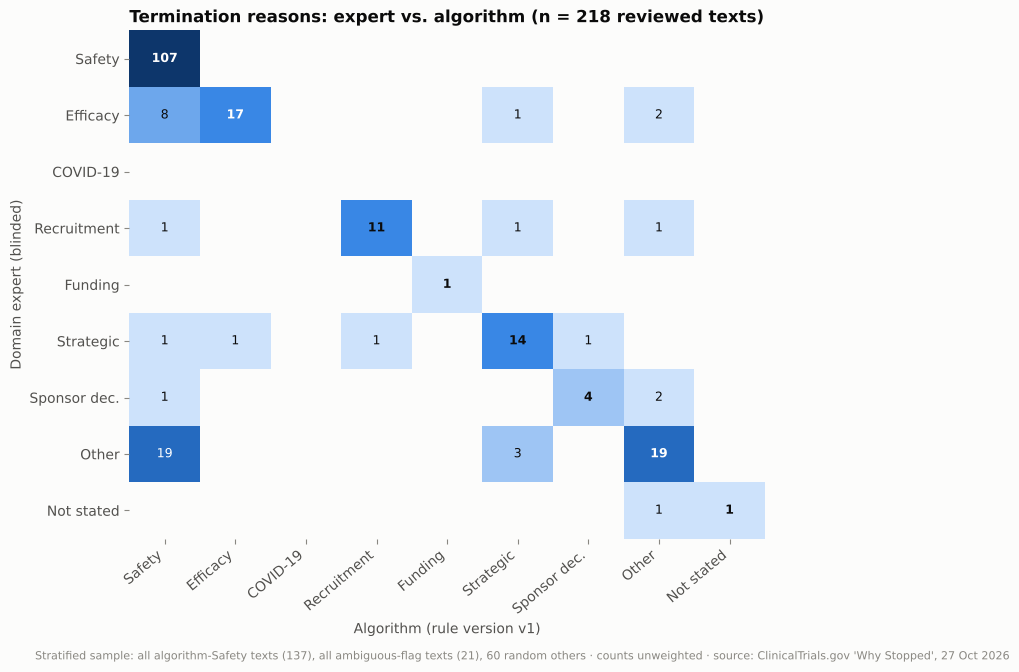

In [17]:
# Confusion matrix (sample counts; rows = expert, columns = algorithm)
cm = pd.crosstab(val["expert"], val["algo"]).reindex(index=CATEGORIES, columns=CATEGORIES, fill_value=0)
short = {"Efficacy/Futility": "Efficacy", "Strategic/Business": "Strategic",
         "Sponsor decision (unspecified)": "Sponsor dec.", "Not stated": "Not stated"}
labels = [short.get(c, c) for c in CATEGORIES]

from matplotlib.colors import ListedColormap
BLUES = ListedColormap(["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(8.2, 6.6))
ax.grid(False)
im = ax.imshow(np.log1p(cm.values), cmap=BLUES, aspect="auto")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=9,
                    color="#ffffff" if np.log1p(v) > np.log1p(cm.values.max()) * 0.6 else vs.INK_PRIMARY,
                    fontweight="bold" if i == j else "normal")
ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("Algorithm (rule version v1)")
ax.set_ylabel("Domain expert (blinded)")
ax.set_title("Termination reasons: expert vs. algorithm (n = 218 reviewed texts)")
for s in ax.spines.values():
    s.set_visible(False)
vs.source_note(fig, "Stratified sample: all algorithm-Safety texts (137), all ambiguous-flag texts (21), "
               "60 random others · counts unweighted · source: ClinicalTrials.gov 'Why Stopped', 27 Oct 2026",
               y=-0.06)
vs.save(fig, PROJECT_DIR / "figures" / "diag_why_stopped_confusion_v1.png")
plt.show()

### 8.2 Safety (multi-label): is any safety aspect a reason?

This is the key figure for research question 1. Algorithm: `reason_Safety` (any Safety match);
expert: column "safety related (yes/no)".

* **Precision** is based on the complete stratum S (census of all 137 algorithm-Safety texts).
* **Recall** needs the false negatives *outside* stratum S. None were found in the sample
  (0 / 21 in A, 0 / 60 in R). Zero events give a point estimate of 100 %, so we add an
  **upper bound for the missed cases** from the exact (Clopper–Pearson) 95 % interval per
  stratum and report the resulting **lower bound for recall**.

In [18]:
N_STRATUM = with_text["stratum"].value_counts()
tp = int(((val["algo_safety"] == 1) & (val["expert_safety"] == 1)).sum())
fp = int(((val["algo_safety"] == 1) & (val["expert_safety"] == 0)).sum())
fn_by_stratum = val[(val["algo_safety"] == 0) & (val["expert_safety"] == 1)].groupby("stratum").size()
n_by_stratum = val.groupby("stratum").size()

prec = tp / (tp + fp)
prec_lo, prec_hi = proportion_confint(tp, tp + fp, method="wilson")
fn_est, fn_upper = 0.0, 0.0
for s in ["A", "R"]:
    k, n = int(fn_by_stratum.get(s, 0)), int(n_by_stratum[s])
    fn_est += k / n * N_STRATUM[s]
    fn_upper += proportion_confint(k, n, method="beta")[1] * N_STRATUM[s]
rec = tp / (tp + fn_est)
rec_lo = tp / (tp + fn_upper)

print(f"Sample: TP {tp} | FP {fp} | FN {int(fn_by_stratum.sum())} | TN {len(val) - tp - fp - int(fn_by_stratum.sum())}")
print(f"Precision Safety : {prec:.1%} (95% CI {prec_lo:.1%}–{prec_hi:.1%})")
print(f"Recall Safety    : {rec:.1%} (lower 95% bound {rec_lo:.1%}; up to {fn_upper:.0f} missed trials possible)")
n_term = len(sample_base)
print(f"\nSafety-related terminations: algorithm v1 {int(sample_base['reason_Safety'].sum())} "
      f"({sample_base['reason_Safety'].mean():.1%})")
print(f"Validated estimate          : {tp + fn_est:.0f} ({(tp + fn_est) / n_term:.1%}), "
      f"upper bound {tp + fn_upper:.0f} ({(tp + fn_upper) / n_term:.1%}) of {n_term:,} terminated trials")

Sample: TP 107 | FP 30 | FN 0 | TN 81
Precision Safety : 78.1% (95% CI 70.5%–84.2%)
Recall Safety    : 100.0% (lower 95% bound 66.1%; up to 55 missed trials possible)

Safety-related terminations: algorithm v1 137 (11.9%)
Validated estimate          : 107 (9.3%), upper bound 162 (14.0%) of 1,154 terminated trials


### 8.3 Validated distribution of primary reasons

Weighted estimate of the *expert's* primary reason for all 1,154 terminated trials (texts not in
the sample are represented by the weights; the 131 trials without text are "Not stated"),
compared with the algorithm (v1).

In [19]:
n_empty = int((sample_base["why_stopped"].fillna("").str.strip() == "").sum())
est = val.groupby("expert")["weight"].sum().reindex(CATEGORIES, fill_value=0)
est["Not stated"] += n_empty
dist = pd.DataFrame({"algorithm v1": sample_base["primary_reason"].value_counts().reindex(CATEGORIES, fill_value=0),
                     "expert (weighted estimate)": est.round(0).astype(int)})
dist["algorithm v1 %"] = (100 * dist["algorithm v1"] / n_term).round(1)
dist["expert %"] = (100 * dist["expert (weighted estimate)"] / n_term).round(1)
print(f"Check: weighted total = {dist['expert (weighted estimate)'].sum():,} (should be ≈ {n_term:,})")
dist

Check: weighted total = 1,154 (should be ≈ 1,154)


,algorithm v1,expert (weighted estimate),algorithm v1 %,expert %
Safety,137,107,11.9,9.3
Efficacy/Futility,108,176,9.4,15.3
COVID-19,28,0,2.4,0.0
Recruitment,148,162,12.8,14.0
Funding,16,14,1.4,1.2
Strategic/Business,298,246,25.8,21.3
Sponsor decision (unspecified),98,74,8.5,6.4
Other,179,215,15.5,18.6
Not stated,142,160,12.3,13.9


### 8.4 Ambiguous texts and error analysis

In [20]:
amb = val[val["ambiguous"]]
not_amb = val[~val["ambiguous"]]
print(f"Ambiguous: {len(amb)} texts, of which algorithm ≠ expert: {(amb['algo'] != amb['expert']).sum()}")
print(f"Agreement without ambiguous texts: unweighted {(not_amb['algo'] == not_amb['expert']).mean():.1%} | "
      f"weighted {np.average(not_amb['algo'] == not_amb['expert'], weights=not_amb['weight']):.1%}")

Ambiguous: 11 texts, of which algorithm ≠ expert: 6
Agreement without ambiguous texts: unweighted 81.6% | weighted 85.2%


In [21]:
# Error types – assigned by transparent text rules (documented, reproducible)
def error_type(r):
    t = str(r["text"]).lower()
    if r["algo"] == r["expert"]:
        return None
    if r["algo_safety"] == 1 and r["expert_safety"] == 0:
        if re.search(r"not (being )?(terminated|stopped|discontinued|halted)\w* (due to|for|because of) (a |any )?safety", t):
            return "Safety FP: negation across 'terminated due to' not detected"
        if re.search(r"safety (profile|data|f-?up|follow|conclusion)|followed up[^.]{0,30}for safety|(adequately|well[- ]?established|sufficient|enough|acceptable|favou?rable|manageable|consistent)[^.]{0,40}safety|safety[^.]{0,40}(characteri[sz]ed|sufficient|demonstrated|collected)|no need for further safety", t):
            return "Safety FP: safety mentioned as information (profile characterised / data sufficient)"
        if re.search(r"benefit|risk", t):
            return "Safety FP: benefit-risk / risk wording without a safety problem"
        return "Safety FP: other"
    return f"{r['algo']} → {r['expert']}"


val["error_type"] = val.apply(error_type, axis=1)
errors = val[val["error_type"].notna()]
summary_errors = (errors.groupby("error_type").agg(n=("review_id", "size"), ambiguous=("ambiguous", "sum"))
                  .sort_values("n", ascending=False))
summary_errors

,n,ambiguous
error_type,,
Safety FP: safety mentioned as information (profile characterised / data sufficient),18,0
Safety FP: other,6,1
Safety FP: benefit-risk / risk wording without a safety problem,4,2
Strategic/Business → Other,3,3
Other → Efficacy/Futility,2,0
Other → Sponsor decision (unspecified),2,0
Safety FP: negation across 'terminated due to' not detected,2,0
Other → Recruitment,1,0
Other → Not stated,1,0


In [22]:
pd.set_option("display.max_colwidth", 140)
errors.sort_values("error_type")[["review_id", "stratum", "algo", "expert", "ambiguous", "error_type", "text"]]

,review_id,stratum,algo,expert,ambiguous,error_type,text
13,14,R,Efficacy/Futility,Strategic/Business,False,Efficacy/Futility → Strategic/Business,"Biomea Fusion, Inc., is no longer pursuing oncology indications for BMF-219. No safety concerns or efficacy observations led to this stu..."
41,42,A,Other,Efficacy/Futility,False,Other → Efficacy/Futility,Interim results of another trial showed inferior activity of treatment
164,165,A,Other,Efficacy/Futility,False,Other → Efficacy/Futility,Study was stopped after interim analysis for all 4 cohorts with results either not fulfilling the pre-planned interim analysis criteria ...
145,146,R,Other,Not stated,False,Other → Not stated,Ended prematurely - The trial never commenced.
156,157,R,Other,Recruitment,False,Other → Recruitment,Recruitment of chronic opioid users was substantially lower than anticipated despite extensive recruitment efforts; the study was theref...
169,170,R,Other,Sponsor decision (unspecified),False,Other → Sponsor decision (unspecified),AstraZeneca has decided to stop further enrollment and the study was terminated when all patients in Part 1 completed their last study v...
193,194,A,Other,Sponsor decision (unspecified),False,Other → Sponsor decision (unspecified),"Based on interim analysis, the Sponsor decided to terminate the study prematurely."
85,86,R,Recruitment,Strategic/Business,False,Recruitment → Strategic/Business,Takeda has decided to not further develop the SHP648 (TAK-748) program. No subjects have been dosed with SHP648. The decision to termina...
91,92,S,Safety,Efficacy/Futility,True,Safety FP: benefit-risk / risk wording without a safety problem,"After risk/benefit analysis, there was a very low probability (4.4%) of meeting the prespecified gating criteria for the Objective Respo..."
163,164,S,Safety,Efficacy/Futility,False,Safety FP: benefit-risk / risk wording without a safety problem,GSK confirmed misrepresentation of preclinical data that supported the rationale for GSK2618960 in MS. This decreased benefit assessment...


In [23]:
val.to_csv(VALIDATION / "why_stopped_validation_results_v1.csv", index=False)
metrics_v1.to_csv(VALIDATION / "why_stopped_metrics_v1.csv")
print("Saved validation results and metrics (v1)")

Saved validation results and metrics (v1)


### 8.5 Summary of the validation (rule version v1, out-of-sample)

| Measure | Result |
|---|---|
| Agreement on the primary reason | 79.8 % unweighted · **83.9 % weighted** |
| Cohen's kappa | 0.69 unweighted · **0.80 weighted** (substantial agreement) |
| Agreement without the 11 ambiguous texts | 81.6 % · 85.2 % weighted |
| **Safety precision** | **78.1 %** (95 % CI 70.5–84.2 %) – 30 of 137 Safety texts were not safety-related |
| **Safety recall** | 100 % in the sample (0 missed); lower 95 % bound 66 % |
| Safety-related terminations | algorithm v1: 137 (11.9 %) → **validated estimate: 107 (9.3 %)**, upper bound 162 (14.0 %) |

**Main error source:** "safety" mentioned as *information*, not as a reason (18 of 30 Safety
false positives): *"safety profile adequately characterised"*, *"enough data collected to
analyse the safety profile"*, *"no need for further safety data"*, *"followed up for safety"*.
Further: benefit-risk wording without a safety problem (4), negation across "not terminated
due to a safety reason" (2), other (6).

**Not covered by the sample:** COVID-19 (no COVID text among the 60 random texts) – precision of
this category is not validated by this sample.

**Caution:** estimates for the non-Safety categories rely on 60 random texts (weight 14.4 each)
and are therefore uncertain (e.g. Efficacy/Futility 9.4 % by the algorithm vs. 15.3 % weighted
expert estimate).

## 9. Rule version v2 and hold-out check (Block 10, part 2)

Rule changes after the expert validation (D39), implemented in `mappings/why_stopped_keywords.csv`
(v1 frozen as `why_stopped_keywords_v1.csv`) and in the classification code:

1. Generic *safety* / *tolerability* / *benefit-risk* wording does not count as a reason when the
   clause describes it as **information** (profile characterised, data sufficient/collected,
   follow-up for safety, unchanged, improve …).
2. Negation reaches across words that only describe the termination itself
   (*"not terminated due to a safety reason"*).
3. Benefit-risk: counted as Safety unless used as information (adapted from the original
   proposal "only with negative direction", because the expert classified e.g.
   *"terminated based on benefit-risk profile assessment"* as Safety).
4. *"no … efficacy"* only with at most one qualifier.
5. *"recruitment … lower than anticipated"* → Recruitment; *"not further develop"* /
   *"no longer pursuing"* → Strategic/Business; *"trial never commenced"* → Not stated.

Because these changes were derived **from** the validation sample, v2 metrics on that sample are
optimistic. The **official accuracy remains v1** (section 8). The changes are checked on new
data: all trials *outside* the sample whose primary reason changed, plus all COVID-19 texts
(not covered by the first sample) – reviewed blinded by the expert.

In [24]:
v1_all = pd.read_parquet(PROCESSED / "why_stopped_classified_v1.parquet")
cmp_v = v1_all[["nct_id", "primary_reason", "reason_Safety"]].merge(
    classified[["nct_id", "primary_reason", "reason_Safety", "why_stopped"]], on="nct_id", suffixes=("_v1", "_v2"))
cmp_v["changed"] = cmp_v["primary_reason_v1"] != cmp_v["primary_reason_v2"]
cmp_v["in_sample"] = cmp_v["nct_id"].isin(key["nct_id"])
print(f"Primary reason changed v1 → v2: {cmp_v['changed'].sum()} trials "
      f"({cmp_v.loc[cmp_v['in_sample'], 'changed'].sum()} inside, {cmp_v.loc[~cmp_v['in_sample'], 'changed'].sum()} outside the sample)")
print(f"Safety (multi-label): v1 {int(cmp_v['reason_Safety_v1'].sum())} → v2 {int(cmp_v['reason_Safety_v2'].sum())}")
changes = (cmp_v[cmp_v["changed"]].groupby(["primary_reason_v1", "primary_reason_v2"]).size()
           .rename("trials").reset_index().sort_values("trials", ascending=False))
changes

Primary reason changed v1 → v2: 29 trials (23 inside, 6 outside the sample)
Safety (multi-label): v1 137 → v2 118


,primary_reason_v1,primary_reason_v2,trials
6,Safety,Other,10
5,Safety,Efficacy/Futility,6
10,Sponsor decision (unspecified),Strategic/Business,3
1,Efficacy/Futility,Strategic/Business,2
3,Other,Recruitment,2
2,Other,Not stated,1
0,Efficacy/Futility,Recruitment,1
4,Other,Strategic/Business,1
7,Safety,Recruitment,1
8,Safety,Sponsor decision (unspecified),1


In [25]:
# v2 on the validation sample (optimistic – rules were revised using this sample)
val2 = val.drop(columns=["algo", "algo_safety"]).merge(
    classified[["nct_id", "primary_reason", "reason_Safety"]].rename(
        columns={"primary_reason": "algo", "reason_Safety": "algo_safety"}), on="nct_id")
metrics_v2 = weighted_metrics(val2, "expert", "algo")
acc2_w = np.average(val2["algo"] == val2["expert"], weights=val2["weight"])
kappa2_w = cohen_kappa_score(val2["expert"], val2["algo"], sample_weight=val2["weight"])
tp2 = int(((val2["algo_safety"] == 1) & (val2["expert_safety"] == 1)).sum())
fp2 = int(((val2["algo_safety"] == 1) & (val2["expert_safety"] == 0)).sum())
fn2 = int(((val2["algo_safety"] == 0) & (val2["expert_safety"] == 1)).sum())
print(f"v2 on the same sample (optimistic): weighted agreement {acc2_w:.1%} (v1 {acc_w:.1%}), "
      f"weighted kappa {kappa2_w:.2f} (v1 {kappa_w:.2f})")
print(f"Safety: TP {tp2} | FP {fp2} | FN {fn2} → precision {tp2 / (tp2 + fp2):.1%} (v1 {prec:.1%})")
pd.concat({"v1 (official)": metrics_v1[["precision_w", "recall_w"]],
           "v2 (optimistic)": metrics_v2[["precision_w", "recall_w"]]}, axis=1).round(2)

v2 on the same sample (optimistic): weighted agreement 90.9% (v1 83.9%), weighted kappa 0.89 (v1 0.80)
Safety: TP 107 | FP 11 | FN 0 → precision 90.7% (v1 78.1%)


v1 (official)          v2 (optimistic)         
                                 precision_w recall_w     precision_w recall_w
category                                                                      
Safety                                  0.78     1.00            0.91     1.00
Efficacy/Futility                       0.91     0.86            0.97     0.87
COVID-19                                 NaN      NaN             NaN      NaN
Recruitment                             0.90     0.82            0.91     0.91
Funding                                 1.00     1.00            1.00     1.00
Strategic/Business                      0.82     0.82            0.84     0.94
Sponsor decision (unspecified)          0.80     0.78            1.00     0.79
Other                                   0.80     0.84            0.91     0.88
Not stated                              1.00     0.50            1.00     1.00

In [26]:
# Hold-out workbook (frozen once created): changed trials outside the sample + all COVID-19 texts
HOLDOUT_FILE = VALIDATION / "why_stopped_holdout_blinded.xlsx"
HOLDOUT_KEY = VALIDATION / "why_stopped_holdout_KEY_do_not_open_before_review.csv"
covid_ids = set(classified.loc[classified["reason_COVID-19"] == 1, "nct_id"])
hold = cmp_v[~cmp_v["in_sample"] & (cmp_v["changed"] | cmp_v["nct_id"].isin(covid_ids))].copy()
hold["selection"] = np.where(hold["changed"], "changed v1→v2", "COVID-19 (v2)")
hold = hold.sample(frac=1, random_state=SEED).reset_index(drop=True)
hold["review_id"] = np.arange(1, len(hold) + 1)
print(f"Hold-out texts: {len(hold)} – {hold['selection'].value_counts().to_dict()}")

if HOLDOUT_FILE.exists() and HOLDOUT_KEY.exists():
    print("Hold-out workbook already exists – frozen, not regenerated.")
else:
    wb2 = Workbook()
    ws2 = wb2.active
    ws2.title = "Review"
    ws2.append(headers)
    for r in hold.itertuples():
        ws2.append([r.review_id, r.nct_id, r.why_stopped, None, None, None, None])
    for cell in ws2[1]:
        cell.font = Font(bold=True)
        cell.fill = header_fill
        cell.alignment = Alignment(wrap_text=True, vertical="top")
    for col, width in zip("ABCDEFG", [9, 14, 90, 30, 16, 30, 30]):
        ws2.column_dimensions[col].width = width
    for row in ws2.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    ws2.freeze_panes = "D2"
    info2 = wb2.create_sheet("Instructions", 0)
    codes = [("Short codes (column D)", "S Safety · E Efficacy/Futility · C COVID-19 · R Recruitment · F Funding · "
              "B Strategic/Business · D Sponsor decision (unspecified) · O Other · N Not stated"),
             ("Short codes (column E)", "y = yes · n = no"),
             ("Column F", "Further categories as codes separated by ';' (e.g. R;B)")]
    for k_, t_ in codes + [("", "")] + INSTRUCTIONS:
        info2.append([k_, t_])
    info2.column_dimensions["A"].width = 30
    info2.column_dimensions["B"].width = 110
    for row in info2.iter_rows():
        row[0].font = Font(bold=True)
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    wb2.save(HOLDOUT_FILE)
    hold[["review_id", "nct_id", "selection", "primary_reason_v1", "primary_reason_v2",
          "reason_Safety_v1", "reason_Safety_v2"]].to_csv(HOLDOUT_KEY, index=False)
    print(f"Saved {HOLDOUT_FILE.relative_to(PROJECT_DIR)} and separate key")

check2 = load_workbook(HOLDOUT_FILE)["Review"]
assert [c.value for c in check2[1]] == headers, "Hold-out workbook columns changed"
print("Blinding check passed (hold-out): only ID, NCT ID and text are shown")

Hold-out texts: 34 – {'COVID-19 (v2)': 28, 'changed v1→v2': 6}
Hold-out workbook already exists – frozen, not regenerated.
Blinding check passed (hold-out): only ID, NCT ID and text are shown


## 10. Hold-out results, final labels and second-rater sample (Block 10, part 3)

Coding rule added for the hold-out review (expert, 2 Nov 2026): **column E for COVID-19 texts –
only safety of the investigational product counts as "yes"; pandemic-related terminations are "no".**

**Caution:** the check of the v2 rule changes on new data comprises only **6 texts** – it can
reveal gross errors, but it is far too small to estimate the accuracy of v2.

In [27]:
HOLD_FILLED = VALIDATION / "why_stopped_holdout_expert_filled.csv"
hold_key = pd.read_csv(HOLDOUT_KEY)
hold_rev, hold_problems = load_review(HOLD_FILLED, expected_ids=hold_key["review_id"])
assert not hold_problems, hold_problems
hold_raw = pd.read_csv(HOLD_FILLED)
hold_blind = pd.read_excel(HOLDOUT_FILE, sheet_name="Review")
chk2 = hold_raw.merge(hold_blind, on="review_id", suffixes=("_f", "_b"))
assert (chk2["nct_id_f"] == chk2["nct_id_b"]).all(), "NCT IDs changed"
print(f"Hold-out review: {len(hold_rev)} rows, all codes valid; texts changed: "
      f"{(chk2['why_stopped (original text)_f'].fillna('') != chk2['why_stopped (original text)_b'].fillna('')).sum()}")

ho = hold_key.merge(hold_rev, on="review_id").merge(
    hold_blind[["review_id", "why_stopped (original text)"]].rename(columns={"why_stopped (original text)": "text"}),
    on="review_id")
changed_ho = ho[ho["selection"].str.startswith("changed")]
covid_ho = ho[ho["selection"].str.startswith("COVID")]

n_ch = len(changed_ho)
v2_ok, v1_ok = (changed_ho["primary_reason_v2"] == changed_ho["expert_primary"]).sum(), \
               (changed_ho["primary_reason_v1"] == changed_ho["expert_primary"]).sum()
print(f"\nChanged trials (n = {n_ch} only): expert agrees with v2 in {v2_ok}, with v1 in {v1_ok}")
k_cov = int((covid_ho["primary_reason_v2"] == covid_ho["expert_primary"]).sum())
lo_cov, hi_cov = proportion_confint(k_cov, len(covid_ho), method="wilson")
print(f"COVID-19 precision: {k_cov} / {len(covid_ho)} = {k_cov / len(covid_ho):.1%} (95% CI {lo_cov:.1%}–{hi_cov:.1%})")
print(f"Safety in hold-out: expert yes {int((ho['expert_safety_related'] == 'yes').sum())}, "
      f"algorithm v2 {int(ho['reason_Safety_v2'].sum())}")
pd.set_option("display.max_colwidth", 120)
ho.loc[(ho["primary_reason_v2"] != ho["expert_primary"]) | ho["selection"].str.startswith("changed"),
       ["review_id", "selection", "primary_reason_v1", "primary_reason_v2", "expert_primary",
        "expert_safety_related", "text"]]

Hold-out review: 34 rows, all codes valid; texts changed: 0

Changed trials (n = 6 only): expert agrees with v2 in 4, with v1 in 2
COVID-19 precision: 25 / 28 = 89.3% (95% CI 72.8%–96.3%)
Safety in hold-out: expert yes 1, algorithm v2 0


,review_id,selection,primary_reason_v1,primary_reason_v2,expert_primary,expert_safety_related,text
3,4,COVID-19 (v2),COVID-19,COVID-19,Other,no,COVID-19 Pandemic sufficient data gathered to achieve the study objective
4,5,COVID-19 (v2),COVID-19,COVID-19,Safety,yes,Attendance at study sites carries risk of COVID-19 infection. Non-attendance at planned study site visits has unacce...
10,11,changed v1→v2,Efficacy/Futility,Strategic/Business,Strategic/Business,no,Business Decision; No Safety Or Efficacy Concerns.
12,13,changed v1→v2,Other,Recruitment,Recruitment,no,Patient inclusion was very tedious and slower than expected. (7 patients in 5 years)
13,14,COVID-19 (v2),COVID-19,COVID-19,Other,no,The good progress of the Italian national vaccination campaign against COVID-19 made impossible to complete the stud...
17,18,changed v1→v2,Other,Strategic/Business,Strategic/Business,no,"Agios is no longer developing its second pyruvate kinase-R (PKR) activator, AG-519, and withdrew its investigational..."
22,23,changed v1→v2,Sponsor decision (unspecified),Strategic/Business,Sponsor decision (unspecified),no,Study was closed early as the sponsor decided not to continue development of certain treatment combinations.
23,24,changed v1→v2,Sponsor decision (unspecified),Strategic/Business,Sponsor decision (unspecified),no,The study was closed because the sponsor decided not to continue the development of certain treatment combinations.
33,34,changed v1→v2,Efficacy/Futility,Recruitment,Recruitment,no,"Insufficient enrollment, no safety or efficacy concerns"


In [28]:
# Consistency check: the same wording labelled differently in the two review rounds
norm = lambda s: re.sub(r"[^a-z ]", "", str(s).lower()).strip()
both = pd.concat([val.assign(round="main review")[["round", "review_id", "text", "expert_primary"]],
                  ho.assign(round="hold-out")[["round", "review_id", "text", "expert_primary"]]])
both["text_core"] = both["text"].map(norm).str.replace(r"^(the )?study was closed (early )?(as|because) ", "", regex=True)
dup = both.groupby("text_core").filter(lambda g: g["expert_primary"].nunique() > 1)
print(f"Same wording, different expert label: {dup['text_core'].nunique()} text(s)")
dup[["round", "review_id", "expert_primary", "text"]]

Same wording, different expert label: 1 text(s)


,round,review_id,expert_primary,text
155,main review,156,Strategic/Business,Study was closed early as the sponsor decided not to continue development of certain treatment combinations.
22,hold-out,23,Sponsor decision (unspecified),Study was closed early as the sponsor decided not to continue development of certain treatment combinations.


### 10.1 Final labels (D41, C2: "expert-adjudicated where available")

* Reviewed by the expert (218 main review + 34 hold-out = 252 trials): **expert label**
* All other terminated trials: **algorithm v2**
* `reason_source` documents the source per trial.

In [29]:
# Expert corrections after unblinding (documented in validation/why_stopped_expert_corrections.csv):
# main review – corrected file (IDs 169, 173); hold-out – IDs 5, 23, 24 (answers to queries a/b)
corrections = pd.read_csv(VALIDATION / "why_stopped_expert_corrections.csv")
main_corr, main_problems = load_review(VALIDATION / "why_stopped_review_expert_filled_corrected.csv",
                                       expected_ids=key["review_id"])
assert not main_problems, main_problems
main_final = key[["review_id", "nct_id"]].merge(main_corr, on="review_id")
ho_final = ho[["review_id", "nct_id", "expert_primary", "expert_safety_related", "expert_comment"]].astype(
    {"expert_comment": "object"})
for c in corrections[corrections["review_round"] == "hold-out"].itertuples():
    ho_final.loc[ho_final["review_id"] == c.review_id, c.field] = c.new_value
changed_main = main_final.merge(val[["review_id", "expert_primary", "expert_safety_related"]], on="review_id",
                                suffixes=("", "_orig"))
n_main_changed = int((changed_main["expert_primary"] != changed_main["expert_primary_orig"]).sum())
print(f"Corrections applied: main review {n_main_changed} label(s) changed "
      f"{changed_main.loc[changed_main['expert_primary'] != changed_main['expert_primary_orig'], 'review_id'].tolist()}, "
      f"hold-out IDs {sorted(corrections.loc[corrections['review_round'] == 'hold-out', 'review_id'].unique().tolist())}")

expert_labels = pd.concat([
    main_final[["nct_id", "expert_primary", "expert_safety_related"]].assign(reason_source="expert (main review)"),
    ho_final[["nct_id", "expert_primary", "expert_safety_related"]].assign(reason_source="expert (hold-out)"),
])
assert expert_labels["nct_id"].is_unique
final = classified.merge(expert_labels, on="nct_id", how="left")
final["reason_source"] = final["reason_source"].fillna("algorithm v2")
final["primary_reason_final"] = final["expert_primary"].fillna(final["primary_reason"])
final["safety_related_final"] = np.where(final["expert_safety_related"].notna(),
                                         (final["expert_safety_related"] == "yes").astype(int),
                                         final["reason_Safety"]).astype(int)

final_dist = pd.DataFrame({
    "algorithm v1": v1_all["primary_reason"].value_counts().reindex(CATEGORIES, fill_value=0),
    "algorithm v2": classified["primary_reason"].value_counts().reindex(CATEGORIES, fill_value=0),
    "final": final["primary_reason_final"].value_counts().reindex(CATEGORIES, fill_value=0)})
final_dist["final %"] = (100 * final_dist["final"] / len(final)).round(1)
print(final["reason_source"].value_counts().to_dict())
print(f"Safety-related (final): {final['safety_related_final'].sum()} "
      f"({final['safety_related_final'].mean():.1%} of {len(final):,} terminated trials)")
final_dist

Corrections applied: main review 2 label(s) changed [169, 173], hold-out IDs [5, 23, 24]


{'algorithm v2': 902, 'expert (main review)': 218, 'expert (hold-out)': 34}
Safety-related (final): 109 (9.4% of 1,154 terminated trials)


,algorithm v1,algorithm v2,final,final %
Safety,137,118,109,9.4
Efficacy/Futility,108,111,116,10.1
COVID-19,28,28,26,2.3
Recruitment,148,152,152,13.2
Funding,16,16,16,1.4
Strategic/Business,298,305,301,26.1
Sponsor decision (unspecified),98,96,98,8.5
Other,179,185,193,16.7
Not stated,142,143,143,12.4


In [30]:
final_cols = ["nct_id", "why_stopped", "primary_reason_final", "safety_related_final", "reason_source",
              "primary_reason", "reason_categories", "reason_Safety", "reason_flags",
              "matched_keywords", "negated_mentions"]
final[final_cols].rename(columns={"primary_reason": "primary_reason_v2", "reason_categories": "reason_categories_v2",
                                  "reason_Safety": "reason_Safety_v2"}) \
    .to_parquet(PROCESSED / "why_stopped_final.parquet", index=False)
ho.to_csv(VALIDATION / "why_stopped_holdout_results.csv", index=False)
print("Saved data/processed/why_stopped_final.parquet (input for notebooks 04–06)")

Saved data/processed/why_stopped_final.parquet (input for notebooks 04–06)


### 10.2 Blinded sample for a second rater (prepared for later)

50 of the 218 main-review texts, stratified by the first expert's primary category (at least
2 per category where available), shuffled, without any labels – for an inter-rater kappa.

In [31]:
CODES = [("Short codes (column D)", "S Safety · E Efficacy/Futility · C COVID-19 · R Recruitment · F Funding · "
          "B Strategic/Business · D Sponsor decision (unspecified) · O Other · N Not stated"),
         ("Short codes (column E)", "y = yes · n = no"),
         ("Column F", "Further categories as codes separated by ';' (e.g. R;B)")]
R2_FILE = VALIDATION / "why_stopped_second_rater_blinded.xlsx"
R2_KEY = VALIDATION / "why_stopped_second_rater_KEY_do_not_open_before_review.csv"
N_R2 = 50
if R2_FILE.exists() and R2_KEY.exists():
    print("Second-rater workbook already exists – frozen, not regenerated.")
else:
    rng = np.random.default_rng(SEED)
    counts = val["expert"].value_counts()
    alloc = (counts / counts.sum() * N_R2).round().astype(int).clip(lower=2).clip(upper=counts)
    while alloc.sum() > N_R2:                       # trim the largest strata to hit exactly 50
        alloc[alloc.idxmax()] -= 1
    while alloc.sum() < N_R2:
        alloc[(counts - alloc).idxmax()] += 1
    r2 = pd.concat([val[val["expert"] == c].sample(int(n), random_state=SEED) for c, n in alloc.items()])
    r2 = r2.sample(frac=1, random_state=SEED).reset_index(drop=True)
    r2["rater2_id"] = np.arange(1, len(r2) + 1)
    wb3 = Workbook()
    ws3 = wb3.active
    ws3.title = "Review"
    ws3.append(headers)
    for r in r2.itertuples():
        ws3.append([r.rater2_id, r.nct_id, r.text, None, None, None, None])
    for cell in ws3[1]:
        cell.font = Font(bold=True)
        cell.fill = header_fill
        cell.alignment = Alignment(wrap_text=True, vertical="top")
    for col, width in zip("ABCDEFG", [9, 14, 90, 30, 16, 30, 30]):
        ws3.column_dimensions[col].width = width
    for row in ws3.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    ws3.freeze_panes = "D2"
    info3 = wb3.create_sheet("Instructions", 0)
    covid_rule = ("COVID-19 rule (column E)", "Only safety of the investigational product counts as 'yes'; "
                  "pandemic-related terminations are 'no'.")
    for k_, t_ in CODES + [covid_rule, ("", "")] + INSTRUCTIONS:
        info3.append([k_, t_])
    info3.column_dimensions["A"].width = 30
    info3.column_dimensions["B"].width = 110
    for row in info3.iter_rows():
        row[0].font = Font(bold=True)
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    wb3.save(R2_FILE)
    r2[["rater2_id", "review_id", "nct_id", "expert"]].to_csv(R2_KEY, index=False)
    print(f"Saved {R2_FILE.relative_to(PROJECT_DIR)} ({len(r2)} texts) and separate key")
    print("Strata (first expert's category):", alloc.to_dict())

Second-rater workbook already exists – frozen, not regenerated.


### 10.3 Validation metrics with the corrected expert labels

The expert corrected 2 labels of the main review after unblinding (IDs 169, 173 → Safety; both
documented). Because corrections made after seeing the algorithm's output can favour the
algorithm, both versions are reported: **as blinded** (section 8) and **after correction**.

In [32]:
valc = val.drop(columns=["expert", "expert_safety"]).merge(
    main_final[["review_id", "expert_primary", "expert_safety_related"]].rename(
        columns={"expert_primary": "expert", "expert_safety_related": "exp_safe_txt"}), on="review_id")
valc["expert_safety"] = (valc["exp_safe_txt"] == "yes").astype(int)
acc_c = np.average(valc["algo"] == valc["expert"], weights=valc["weight"])
kap_c = cohen_kappa_score(valc["expert"], valc["algo"], sample_weight=valc["weight"])
tp_c = int(((valc["algo_safety"] == 1) & (valc["expert_safety"] == 1)).sum())
fp_c = int(((valc["algo_safety"] == 1) & (valc["expert_safety"] == 0)).sum())
lo_c, hi_c = proportion_confint(tp_c, tp_c + fp_c, method="wilson")
print("Rule version v1 vs. expert   | as blinded | after correction")
print(f"Weighted agreement            | {acc_w:.1%}      | {acc_c:.1%}")
print(f"Weighted kappa                | {kappa_w:.2f}       | {kap_c:.2f}")
print(f"Safety precision              | {prec:.1%}      | {tp_c / (tp_c + fp_c):.1%} (95% CI {lo_c:.1%}–{hi_c:.1%})")

Rule version v1 vs. expert   | as blinded | after correction
Weighted agreement            | 83.9%      | 83.9%
Weighted kappa                | 0.80       | 0.80
Safety precision              | 78.1%      | 78.8% (95% CI 71.3%–84.8%)


### 10.4 Intra-rater reliability (test-retest)

No second rater was available. The expert re-rated 50 of her 218 main-review texts herself after a
few days (blinded workbook, shuffled). Test-retest compares the **original** re-rating (before any
correction) with her **original** main-review rating. A corrected version of the re-rating exists
but is only kept as documentation and is not used for reliability. Memory effects are possible.

In [33]:
RETEST_ORIG = VALIDATION / "why_stopped_retest_original.csv"
r2_key = pd.read_csv(R2_KEY)
if not RETEST_ORIG.exists():
    print("Original re-rating (before correction) not yet available – test-retest not computed.")
else:
    retest, rt_problems = load_review(RETEST_ORIG, expected_ids=r2_key["rater2_id"])
    assert not rt_problems, rt_problems
    tr = r2_key.merge(retest.rename(columns={"review_id": "rater2_id"}), on="rater2_id") \
               .merge(val[["review_id", "expert", "expert_safety_related"]], on="review_id",
                      suffixes=("_retest", "_first"))
    agree_p = (tr["expert_primary"] == tr["expert_first"]).mean()
    kap_p = cohen_kappa_score(tr["expert_first"], tr["expert_primary"])
    kap_s = cohen_kappa_score(tr["expert_safety_related_first"], tr["expert_safety_related_retest"])
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(2000):
        s = tr.sample(len(tr), replace=True, random_state=int(rng.integers(1e9)))
        boot.append(cohen_kappa_score(s["expert_first"], s["expert_primary"]))
    lo_k, hi_k = np.nanpercentile(boot, [2.5, 97.5])
    print(f"Test-retest (n = {len(tr)}): agreement primary {agree_p:.1%}, Cohen's kappa {kap_p:.2f} "
          f"(bootstrap 95% CI {lo_k:.2f}–{hi_k:.2f}); kappa safety yes/no {kap_s:.2f}")

    # Output with unambiguous column names. "expert_retest" from the merge is only the first-round label
    # copied from the sample key (identical to "expert_first") and is therefore dropped.
    assert (tr["expert_retest"] == tr["expert_first"]).all()
    out = tr.drop(columns=["expert_retest"]).rename(columns={
        "rater2_id": "retest_id",
        "expert_primary": "retest_primary_original", "expert_safety_related_retest": "retest_safety_original",
        "expert_other": "retest_other_original", "expert_comment": "retest_comment_original",
        "expert_first": "first_round_primary", "expert_safety_related_first": "first_round_safety"})
    RETEST_CORR = VALIDATION / "why_stopped_retest_corrected_documented.csv"
    if RETEST_CORR.exists():   # documented re-assessment – NOT used for reliability
        rc, rc_problems = load_review(RETEST_CORR, expected_ids=r2_key["rater2_id"])
        assert not rc_problems, rc_problems
        rc = rc.rename(columns={"review_id": "retest_id", "expert_primary": "retest_primary_corrected_doc",
                                "expert_safety_related": "retest_safety_corrected_doc"})
        out = out.merge(rc[["retest_id", "retest_primary_corrected_doc", "retest_safety_corrected_doc"]],
                        on="retest_id", how="left")
        n_chg = int((out["retest_primary_corrected_doc"] != out["retest_primary_original"]).sum())
        print(f"Corrected re-rating (documentation only): primary label differs in {n_chg} of {len(out)} texts")
    # the published file must reproduce the reported values
    assert np.isclose(cohen_kappa_score(out["first_round_primary"], out["retest_primary_original"]), kap_p)
    out.to_csv(VALIDATION / "why_stopped_retest_results.csv", index=False)
    print("Columns:", ", ".join(out.columns))

Test-retest (n = 50): agreement primary 84.0%, Cohen's kappa 0.78 (bootstrap 95% CI 0.65–0.91); kappa safety yes/no 0.96
Corrected re-rating (documentation only): primary label differs in 9 of 50 texts
Columns: retest_id, review_id, nct_id, retest_primary_original, retest_safety_original, retest_other_original, retest_comment_original, first_round_primary, first_round_safety, retest_primary_corrected_doc, retest_safety_corrected_doc


### 10.5 Summary of Block 10

**Validation (official, rule version v1, out-of-sample):** weighted agreement 83.9 %, weighted
kappa 0.80; Safety precision 78.1 % as blinded (78.8 % after the expert's 2 documented corrections),
Safety recall 100 % in the sample (lower 95 % bound 66 %).

**Rule version v2** (revised with the validation sample): optimistic on that sample (weighted
agreement 90.9 %, Safety precision 90.7 %, no Safety case lost). The check on **new data comprises
only 6 changed trials** (expert agreed with v2 in 4, with v1 in 2) – it shows no gross errors but
does not allow an accuracy estimate. Both v1-favouring cases were the borderline wording "sponsor
decided not to continue development of certain treatment combinations", now harmonised by the
expert to **Strategic/Business** (a reason is given).

**COVID-19:** precision 25 / 28 = 89 % (95 % CI 73–96 %) against the hold-out review as given;
after correction K4 (ID 5 → COVID-19 per D42) 26 / 28.

**Expert corrections after unblinding** (all documented in
`validation/why_stopped_expert_corrections.csv`): main review IDs 169, 173 → Safety; hold-out IDs
23, 24 → Strategic/Business, ID 5 → COVID-19 / no.

**Final labels** (D41): expert label for 252 reviewed trials, algorithm v2 for 902 →
`data/processed/why_stopped_final.parquet`. **Safety-related terminations: 109 of 1,154 (9.4 %)**;
primary reasons: Strategic/Business 26.1 % · Other 16.7 % · Recruitment 13.2 % · Not stated
12.4 % · Efficacy/Futility 10.1 % · **Safety 9.4 %** · Sponsor decision 8.5 % · COVID-19 2.3 % ·
Funding 1.4 %.

**Reliability:** one rater only (no inter-rater kappa). **Intra-rater test-retest** on 50 texts
re-rated by the same expert after a few days (original re-rating, before correction): agreement on
the primary reason **84 %**, Cohen's kappa **0.78** (bootstrap 95 % CI 0.65–0.91); safety yes/no
kappa **0.96** (98 % agreement). A memory effect may inflate these values. The later corrected
re-rating (9 primary labels changed) is kept as documentation only.